In [71]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import joblib


In [72]:

df = pd.read_csv("slope_stability_dataset.csv")

df.head()


,unit_weight_knm,cohesion_kpa,internal_friction_angle_,slope_angle_,slope_height_m,pore_water_pressure_ratio,reinforcement_type,reinforcement,fs,timestamp,rockfall_risk
0,18.745401,21.813837,38.249958,41.907228,18.451042,0.847237,Drainage,3,2.613692,2026-02-23 02:09:08.417622,0
1,24.507143,19.981044,24.612800,32.964623,9.266800,0.494517,Geosynthetics,2,2.241626,2026-02-23 02:10:08.417622,0
2,22.319939,12.926926,28.665992,58.224926,10.686165,0.195466,Retaining Wall,0,1.568244,2026-02-23 02:11:08.417622,1
3,20.986585,32.327000,36.582016,20.948923,13.130201,0.736642,Drainage,3,3.000000,2026-02-23 02:12:08.417622,0
4,16.560186,26.448087,32.052234,39.392821,14.164400,0.418678,Soil Nailing,1,3.000000,2026-02-23 02:13:08.417622,0


In [73]:
import pandas as pd


df = pd.read_csv("slope_stability_dataset.csv")


df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(' ', '_')
    .str.replace(r'[^\w\s]', '', regex=True)
)


rename_map = {
    'factor_of_safety_fs': 'fs',
    'reinforcement_numeric': 'reinforcement',
}
df.rename(columns=rename_map, inplace=True)

assert 'fs' in df.columns, "Missing column: fs"
assert 'reinforcement' in df.columns, "Missing column: reinforcement"


if 'rockfall_risk' not in df.columns:
    df['rockfall_risk'] = ((df['fs'] < 1.4) | (df['reinforcement'] < 0.4)).astype(int)


df.dropna(subset=['fs', 'reinforcement'], inplace=True)


df.head()


,unit_weight_knm,cohesion_kpa,internal_friction_angle_,slope_angle_,slope_height_m,pore_water_pressure_ratio,reinforcement_type,reinforcement,fs,timestamp,rockfall_risk
0,18.745401,21.813837,38.249958,41.907228,18.451042,0.847237,Drainage,3,2.613692,2026-02-23 02:09:08.417622,0
1,24.507143,19.981044,24.612800,32.964623,9.266800,0.494517,Geosynthetics,2,2.241626,2026-02-23 02:10:08.417622,0
2,22.319939,12.926926,28.665992,58.224926,10.686165,0.195466,Retaining Wall,0,1.568244,2026-02-23 02:11:08.417622,1
3,20.986585,32.327000,36.582016,20.948923,13.130201,0.736642,Drainage,3,3.000000,2026-02-23 02:12:08.417622,0
4,16.560186,26.448087,32.052234,39.392821,14.164400,0.418678,Soil Nailing,1,3.000000,2026-02-23 02:13:08.417622,0


In [74]:

df.isnull().sum()
df.dropna(subset=['fs', 'reinforcement'], inplace=True)

df['rockfall_risk'].value_counts()


rockfall_risk
0    6767
1    3233
Name: count, dtype: int64

In [75]:


features = ['fs', 'reinforcement']

X = df[features]
y = df['rockfall_risk']


In [76]:

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [77]:

model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)


joblib.dump(model, "rockfall_model_fs_reinforcement.pkl")
print("Model saved as rockfall_model_fs_reinforcement.pkl")


Model saved as rockfall_model_fs_reinforcement.pkl


Accuracy: 1.0

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00      1336
           1       1.00      1.00      1.00       664

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000



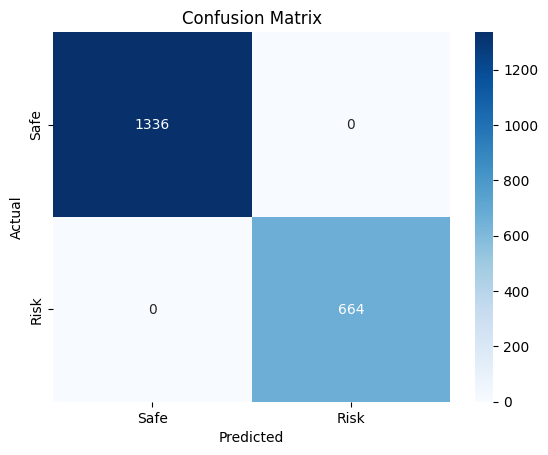

In [78]:

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))


cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=["Safe", "Risk"], yticklabels=["Safe", "Risk"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()


In [79]:

logreg = LogisticRegression()
logreg.fit(X_train, y_train)
y_pred_log = logreg.predict(X_test)

print("Logistic Regression Accuracy:", accuracy_score(y_test, y_pred_log))


Logistic Regression Accuracy: 0.9325


In [80]:

model = joblib.load("rockfall_model_fs_reinforcement.pkl")

sample = pd.DataFrame([[1.2, 0.3]], columns=['fs', 'reinforcement'])
model.predict(sample)


array([1])

In [81]:

from sklearn.model_selection import GridSearchCV


param_grid = {
    'n_estimators': [50, 100, 150],
    'max_depth': [None, 5, 10],
    'min_samples_split': [2, 5, 10],
}


rf = RandomForestClassifier(random_state=42)


grid_search = GridSearchCV(estimator=rf, param_grid=param_grid, 
                           cv=5, scoring='accuracy', n_jobs=-1, verbose=1)
grid_search.fit(X_train, y_train)


best_rf = grid_search.best_estimator_
print("Best Parameters:", grid_search.best_params_)

joblib.dump(best_rf, "rockfall_model_tuned.pkl")


Fitting 5 folds for each of 27 candidates, totalling 135 fits
Best Parameters: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 50}


['rockfall_model_tuned.pkl']

In [82]:
import joblib


joblib.dump(best_rf, 'rockfall_model_fs_reinforcement.pkl')  # same name used in your Streamlit code
print(" Model saved as rockfall_model_fs_reinforcement.pkl")


 Model saved as rockfall_model_fs_reinforcement.pkl


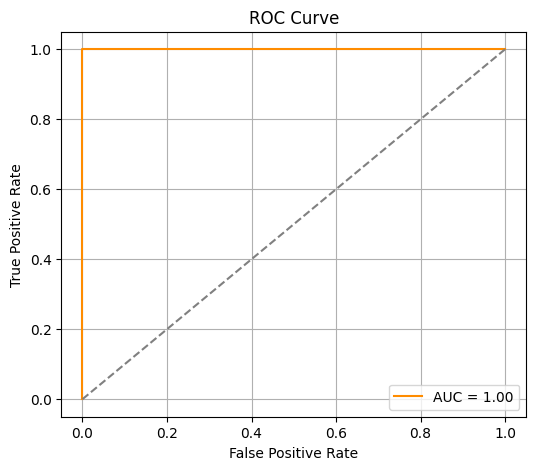

In [83]:

from sklearn.metrics import roc_curve, roc_auc_score


y_probs = best_rf.predict_proba(X_test)[:, 1]


fpr, tpr, thresholds = roc_curve(y_test, y_probs)
roc_auc = roc_auc_score(y_test, y_probs)


plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.2f}", color='darkorange')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.grid(True)
plt.show()


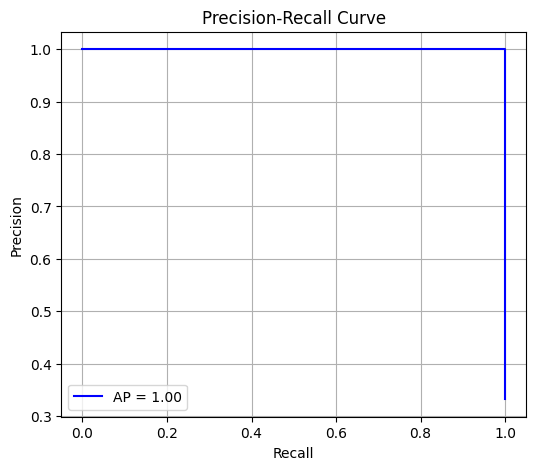

In [84]:

from sklearn.metrics import precision_recall_curve, average_precision_score

precision, recall, _ = precision_recall_curve(y_test, y_probs)
avg_prec = average_precision_score(y_test, y_probs)

plt.figure(figsize=(6, 5))
plt.plot(recall, precision, color='blue', label=f'AP = {avg_prec:.2f}')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.grid(True)
plt.show()


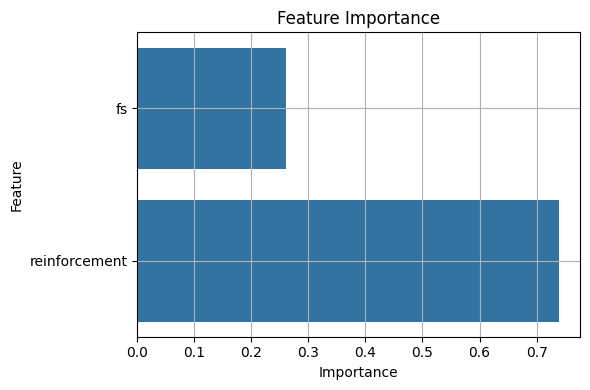

In [85]:

importances = best_rf.feature_importances_
feature_names = X.columns


plt.figure(figsize=(6, 4))
sns.barplot(x=importances, y=feature_names)
plt.title('Feature Importance')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.grid(True)
plt.tight_layout()
plt.show()


In [86]:

logreg = LogisticRegression()
logreg.fit(X_train, y_train)
logreg_pred = logreg.predict(X_test)

print("Logistic Regression Accuracy:", accuracy_score(y_test, logreg_pred))
print("\nClassification Report:\n", classification_report(y_test, logreg_pred))


Logistic Regression Accuracy: 0.9325

Classification Report:
               precision    recall  f1-score   support

           0       0.96      0.94      0.95      1336
           1       0.88      0.92      0.90       664

    accuracy                           0.93      2000
   macro avg       0.92      0.93      0.92      2000
weighted avg       0.93      0.93      0.93      2000



In [87]:
import os
os.getcwd()


'C:\\Users\\Lenovo\\AI-Based-Rockfall-Prediction-And-Alert-System-In-Open-Pit-Mines'

In [88]:
import joblib
import os

project_dir = r"C:\Users\Lenovo\Desktop\AI Based Rockfall Prediction And Alert System in Open Pit Mines"


model_path = os.path.join(project_dir, "rockfall_model_fs_reinforcement.pkl")
joblib.dump(best_rf, model_path)

print(f" Model saved at: {model_path}")


 Model saved at: C:\Users\Lenovo\Desktop\AI Based Rockfall Prediction And Alert System in Open Pit Mines\rockfall_model_fs_reinforcement.pkl


In [89]:
import joblib

joblib.dump(best_rf, "rockfall_model_fs_reinforcement.pkl")


['rockfall_model_fs_reinforcement.pkl']

In [90]:
import joblib

joblib.dump(model, "rockfall_model_fs_reinforcement.pkl")


['rockfall_model_fs_reinforcement.pkl']

import joblib

model = joblib.load("rockfall_model_fs_reinforcement.pkl")


In [91]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix


from sklearn.ensemble import RandomForestClassifier

In [92]:
import os
print(os.getcwd())

C:\Users\Lenovo\AI-Based-Rockfall-Prediction-And-Alert-System-In-Open-Pit-Mines


In [93]:
import os
print(os.listdir())

['.git', '.gitignore', '.idea', '.ipynb_checkpoints', '.venv', 'create_model.py', 'encoder.pkl', 'load_model.py', 'mine.png', 'model.py', 'README.md', 'reinforcement_encoder.pkl', 'requirements.txt', 'rockfall_model.pkl', 'rockfall_model_advanced.pkl', 'rockfall_model_fs_reinforcement.pkl', 'Rockfall_Model_Training.ipynb', 'rockfall_model_tuned.pkl', 'seismic-bumps.csv', 'slope_stability_dataset.csv', 'underground_dataset.csv', 'underground_encoder.pkl', 'underground_mine.png', 'underground_mine1.png', 'underground_rockfall_model.pkl', 'underground_scaler.pkl']


In [94]:
import os

files_to_delete = [
    "underground_encoder.pkl",
    "underground_rockfall_model.pkl"
]

for file in files_to_delete:
    if os.path.exists(file):
        os.remove(file)
        print(f"{file} deleted successfully.")
    else:
        print(f"{file} not found.")

underground_encoder.pkl deleted successfully.
underground_rockfall_model.pkl deleted successfully.


In [95]:
import pandas as pd

df = pd.read_csv("seismic-bumps.csv")

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (2584, 19)


,seismic,seismoacoustic,shift,genergy,gpuls,gdenergy,gdpuls,hazard,nbumps,nbumps2,nbumps3,nbumps4,nbumps5,nbumps6,nbumps7,nbumps89,energy,maxenergy,class
0,a,a,N,15180,48,-72,-72,a,0,0,0,0,0,0,0,0,0,0,0
1,a,a,N,14720,33,-70,-79,a,1,0,1,0,0,0,0,0,2000,2000,0
2,a,a,N,8050,30,-81,-78,a,0,0,0,0,0,0,0,0,0,0,0
3,a,a,N,28820,171,-23,40,a,1,0,1,0,0,0,0,0,3000,3000,0
4,a,a,N,12640,57,-63,-52,a,0,0,0,0,0,0,0,0,0,0,0


In [96]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2584 entries, 0 to 2583
Data columns (total 19 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   seismic         2584 non-null   object
 1   seismoacoustic  2584 non-null   object
 2   shift           2584 non-null   object
 3   genergy         2584 non-null   int64 
 4   gpuls           2584 non-null   int64 
 5   gdenergy        2584 non-null   int64 
 6   gdpuls          2584 non-null   int64 
 7   hazard          2584 non-null   object
 8   nbumps          2584 non-null   int64 
 9   nbumps2         2584 non-null   int64 
 10  nbumps3         2584 non-null   int64 
 11  nbumps4         2584 non-null   int64 
 12  nbumps5         2584 non-null   int64 
 13  nbumps6         2584 non-null   int64 
 14  nbumps7         2584 non-null   int64 
 15  nbumps89        2584 non-null   int64 
 16  energy          2584 non-null   int64 
 17  maxenergy       2584 non-null   int64 
 18  class   

In [97]:
print(df["class"].value_counts())

class
0    2414
1     170
Name: count, dtype: int64


In [98]:
from sklearn.preprocessing import LabelEncoder

categorical_cols = ["seismic", "seismoacoustic", "shift", "hazard"]

le_dict = {}

for col in categorical_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    le_dict[col] = le  # store encoders for later use

df.head()

,seismic,seismoacoustic,shift,genergy,gpuls,gdenergy,gdpuls,hazard,nbumps,nbumps2,nbumps3,nbumps4,nbumps5,nbumps6,nbumps7,nbumps89,energy,maxenergy,class
0,0,0,0,15180,48,-72,-72,0,0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,14720,33,-70,-79,0,1,0,1,0,0,0,0,0,2000,2000,0
2,0,0,0,8050,30,-81,-78,0,0,0,0,0,0,0,0,0,0,0,0
3,0,0,0,28820,171,-23,40,0,1,0,1,0,0,0,0,0,3000,3000,0
4,0,0,0,12640,57,-63,-52,0,0,0,0,0,0,0,0,0,0,0,0


In [99]:
X = df.drop("class", axis=1)
y = df["class"]

In [100]:
from imblearn.over_sampling import SMOTE

sm = SMOTE(random_state=42)
X_resampled, y_resampled = sm.fit_resample(X, y)

print("After SMOTE balancing:")
print(y_resampled.value_counts())

After SMOTE balancing:
class
0    2414
1    2414
Name: count, dtype: int64


In [101]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_resampled)

In [102]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y_resampled,
    test_size=0.2,
    random_state=42
)

In [103]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=300,
    max_depth=15,
    class_weight="balanced",
    random_state=42
)

model.fit(X_train, y_train)

,n_estimators,300
,criterion,'gini'
,max_depth,15
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [104]:
from sklearn.metrics import classification_report, confusion_matrix

y_pred = model.predict(X_test)

print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

[[449  52]
 [ 31 434]]
              precision    recall  f1-score   support

           0       0.94      0.90      0.92       501
           1       0.89      0.93      0.91       465

    accuracy                           0.91       966
   macro avg       0.91      0.91      0.91       966
weighted avg       0.92      0.91      0.91       966



In [105]:
y_prob = model.predict_proba(X_test)[:, 1]

y_pred_custom = (y_prob > 0.4).astype(int)

from sklearn.metrics import classification_report, confusion_matrix

print(confusion_matrix(y_test, y_pred_custom))
print(classification_report(y_test, y_pred_custom))

[[420  81]
 [ 20 445]]
              precision    recall  f1-score   support

           0       0.95      0.84      0.89       501
           1       0.85      0.96      0.90       465

    accuracy                           0.90       966
   macro avg       0.90      0.90      0.90       966
weighted avg       0.90      0.90      0.90       966



In [106]:
from sklearn.ensemble import RandomForestClassifier

final_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=15,
    class_weight="balanced",
    random_state=42
)

final_model.fit(X_train, y_train)

,n_estimators,300
,criterion,'gini'
,max_depth,15
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [107]:
import pickle

with open("underground_rockfall_model.pkl", "wb") as f:
    pickle.dump(final_model, f)

with open("underground_scaler.pkl", "wb") as f:
    pickle.dump(scaler, f)


with open("underground_encoder.pkl", "wb") as f:
    pickle.dump(le_dict, f)

print("Underground model saved successfully.")

Underground model saved successfully.


<Figure size 640x480 with 0 Axes>

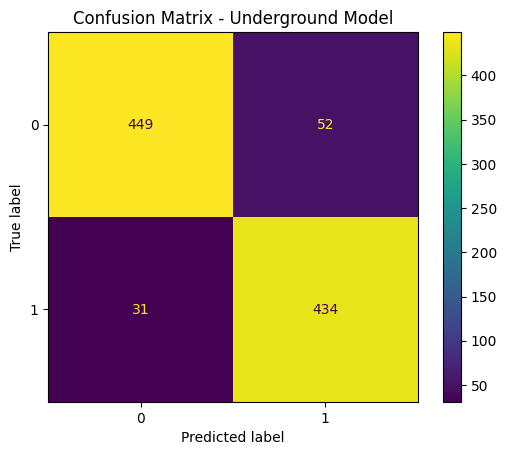

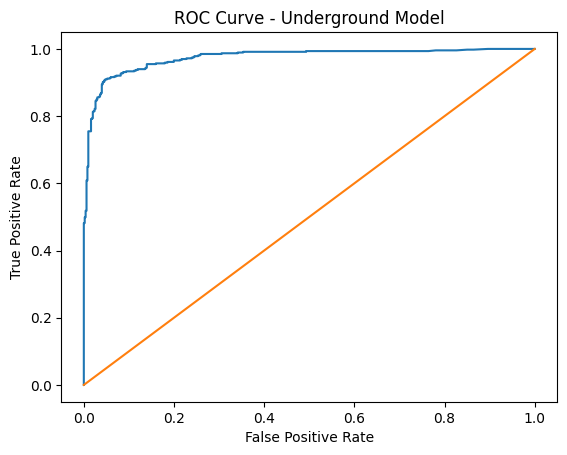

ROC AUC Score: 0.9738673191251904


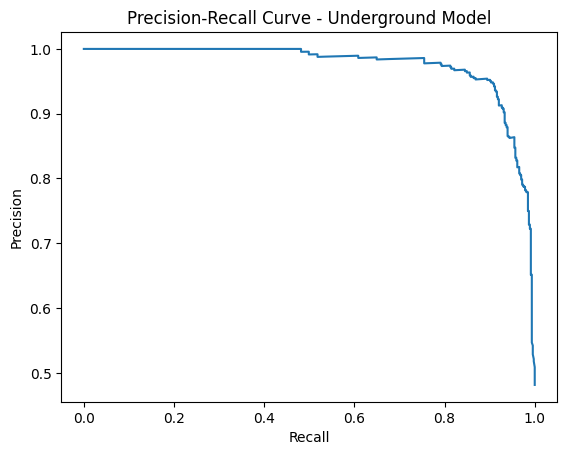

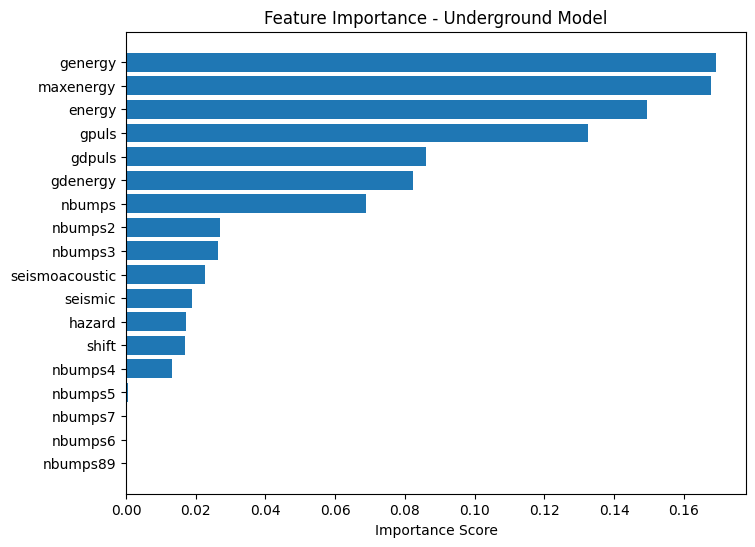

In [109]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, roc_curve, auc, precision_recall_curve, ConfusionMatrixDisplay
from imblearn.over_sampling import SMOTE

df = pd.read_csv("seismic-bumps.csv")

categorical_cols = ["seismic", "seismoacoustic", "shift", "hazard"]

for col in categorical_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])


X = df.drop("class", axis=1)
y = df["class"]

sm = SMOTE(random_state=42)
X_resampled, y_resampled = sm.fit_resample(X, y)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_resampled)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y_resampled, test_size=0.2, random_state=42
)


model = RandomForestClassifier(
    n_estimators=300,
    max_depth=15,
    class_weight="balanced",
    random_state=42
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

plt.figure()
disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(y_test, y_pred))
disp.plot()
plt.title("Confusion Matrix - Underground Model")
plt.show()

fpr, tpr, _ = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Underground Model")
plt.show()

print("ROC AUC Score:", roc_auc)

precision, recall, _ = precision_recall_curve(y_test, y_prob)

plt.figure()
plt.plot(recall, precision)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Underground Model")
plt.show()

importances = model.feature_importances_
features = X.columns
indices = np.argsort(importances)

plt.figure(figsize=(8,6))
plt.barh(features[indices], importances[indices])
plt.xlabel("Importance Score")
plt.title("Feature Importance - Underground Model")
plt.show()